In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score, mean_squared_error

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Ml project /archive (6).zip"
extract_path = "/content/"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Assuming the CSV file is directly in the extracted content or in a common subdirectory
# Let's try to find the file or assume a common name/path after extraction.
# For now, I'll use a placeholder and then you might need to adjust after seeing the extracted files.
# A common extracted folder name might be 'crop_production_data' or 'archive (6)' itself
# Let's try listing the content to be sure
print(os.listdir(extract_path))

# Placeholder path, will need to be updated after inspecting the extracted files
df = pd.read_csv("/content/crop_production.csv") # This will likely fail, we need to inspect the extracted files.
df[:5]


['.config', 'drive', 'crop_production.csv', 'sample_data']


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0


In [ ]:
df.isnull().sum()

,0
State_Name,0
District_Name,0
Crop_Year,0
Season,0
Crop,0
Area,0
Production,3730


In [ ]:
print(df.head())

                    State_Name District_Name  Crop_Year       Season  \
0  Andaman and Nicobar Islands      NICOBARS       2000  Kharif        
1  Andaman and Nicobar Islands      NICOBARS       2000  Kharif        
2  Andaman and Nicobar Islands      NICOBARS       2000  Kharif        
3  Andaman and Nicobar Islands      NICOBARS       2000  Whole Year    
4  Andaman and Nicobar Islands      NICOBARS       2000  Whole Year    

                  Crop    Area  Production  
0             Arecanut  1254.0      2000.0  
1  Other Kharif pulses     2.0         1.0  
2                 Rice   102.0       321.0  
3               Banana   176.0       641.0  
4            Cashewnut   720.0       165.0  


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246091 entries, 0 to 246090
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   State_Name     246091 non-null  object 
 1   District_Name  246091 non-null  object 
 2   Crop_Year      246091 non-null  int64  
 3   Season         246091 non-null  object 
 4   Crop           246091 non-null  object 
 5   Area           246091 non-null  float64
 6   Production     242361 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 13.1+ MB
None


In [ ]:
print(df.describe())

           Crop_Year          Area    Production
count  246091.000000  2.460910e+05  2.423610e+05
mean     2005.643018  1.200282e+04  5.825034e+05
std         4.952164  5.052340e+04  1.706581e+07
min      1997.000000  4.000000e-02  0.000000e+00
25%      2002.000000  8.000000e+01  8.800000e+01
50%      2006.000000  5.820000e+02  7.290000e+02
75%      2010.000000  4.392000e+03  7.023000e+03
max      2015.000000  8.580100e+06  1.250800e+09


In [ ]:
df_model = df.drop(["District_Name", "Crop_Year"], axis=1)

# Convert categorical columns into dummy variables
df_model = pd.get_dummies(df_model, drop_first=True)

In [ ]:
# Droping Nan Values
data = df.dropna()
print(data.shape)
test = df[~df["Production"].notna()].drop("Production",axis=1)
print(test.shape)

(242361, 7)
(3730, 6)


In [ ]:
sum_maxp = data["Production"].sum()
data["percent_of_production"] = data["Production"].map(lambda x:(x/sum_maxp)*100)

/tmp/ipykernel_1356/1048416122.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["percent_of_production"] = data["Production"].map(lambda x:(x/sum_maxp)*100)


In [ ]:
df[:5]

,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0


Data Visualization

<Axes: xlabel='Crop_Year', ylabel='Production'>

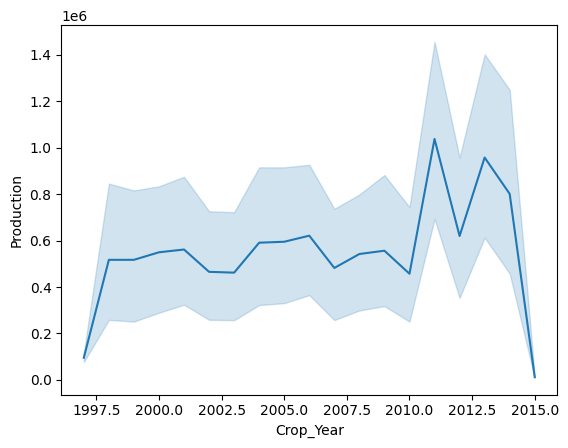

In [ ]:
sns.lineplot(x="Crop_Year", y="Production", data=data)

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32],
 [Text(0, 0, 'Andaman and Nicobar Islands'),
  Text(1, 0, 'Andhra Pradesh'),
  Text(2, 0, 'Arunachal Pradesh'),
  Text(3, 0, 'Assam'),
  Text(4, 0, 'Bihar'),
  Text(5, 0, 'Chandigarh'),
  Text(6, 0, 'Chhattisgarh'),
  Text(7, 0, 'Dadra and Nagar Haveli'),
  Text(8, 0, 'Goa'),
  Text(9, 0, 'Gujarat'),
  Text(10, 0, 'Haryana'),
  Text(11, 0, 'Himachal Pradesh'),
  Text(12, 0, 'Jammu and Kashmir '),
  Text(13, 0, 'Jharkhand'),
  Text(14, 0, 'Karnataka'),
  Text(15, 0, 'Kerala'),
  Text(16, 0, 'Madhya Pradesh'),
  Text(17, 0, 'Maharashtra'),
  Text(18, 0, 'Manipur'),
  Text(19, 0, 'Meghalaya'),
  Text(20, 0, 'Mizoram'),
  Text(21, 0, 'Nagaland'),
  Text(22, 0, 'Odisha'),
  Text(23, 0, 'Puducherry'),
  Text(24, 0, 'Punjab'),
  Text(25, 0, 'Rajasthan'),
  Text(26, 0, 'Sikkim'),
  Text(27, 0, 'Tamil Nadu'),

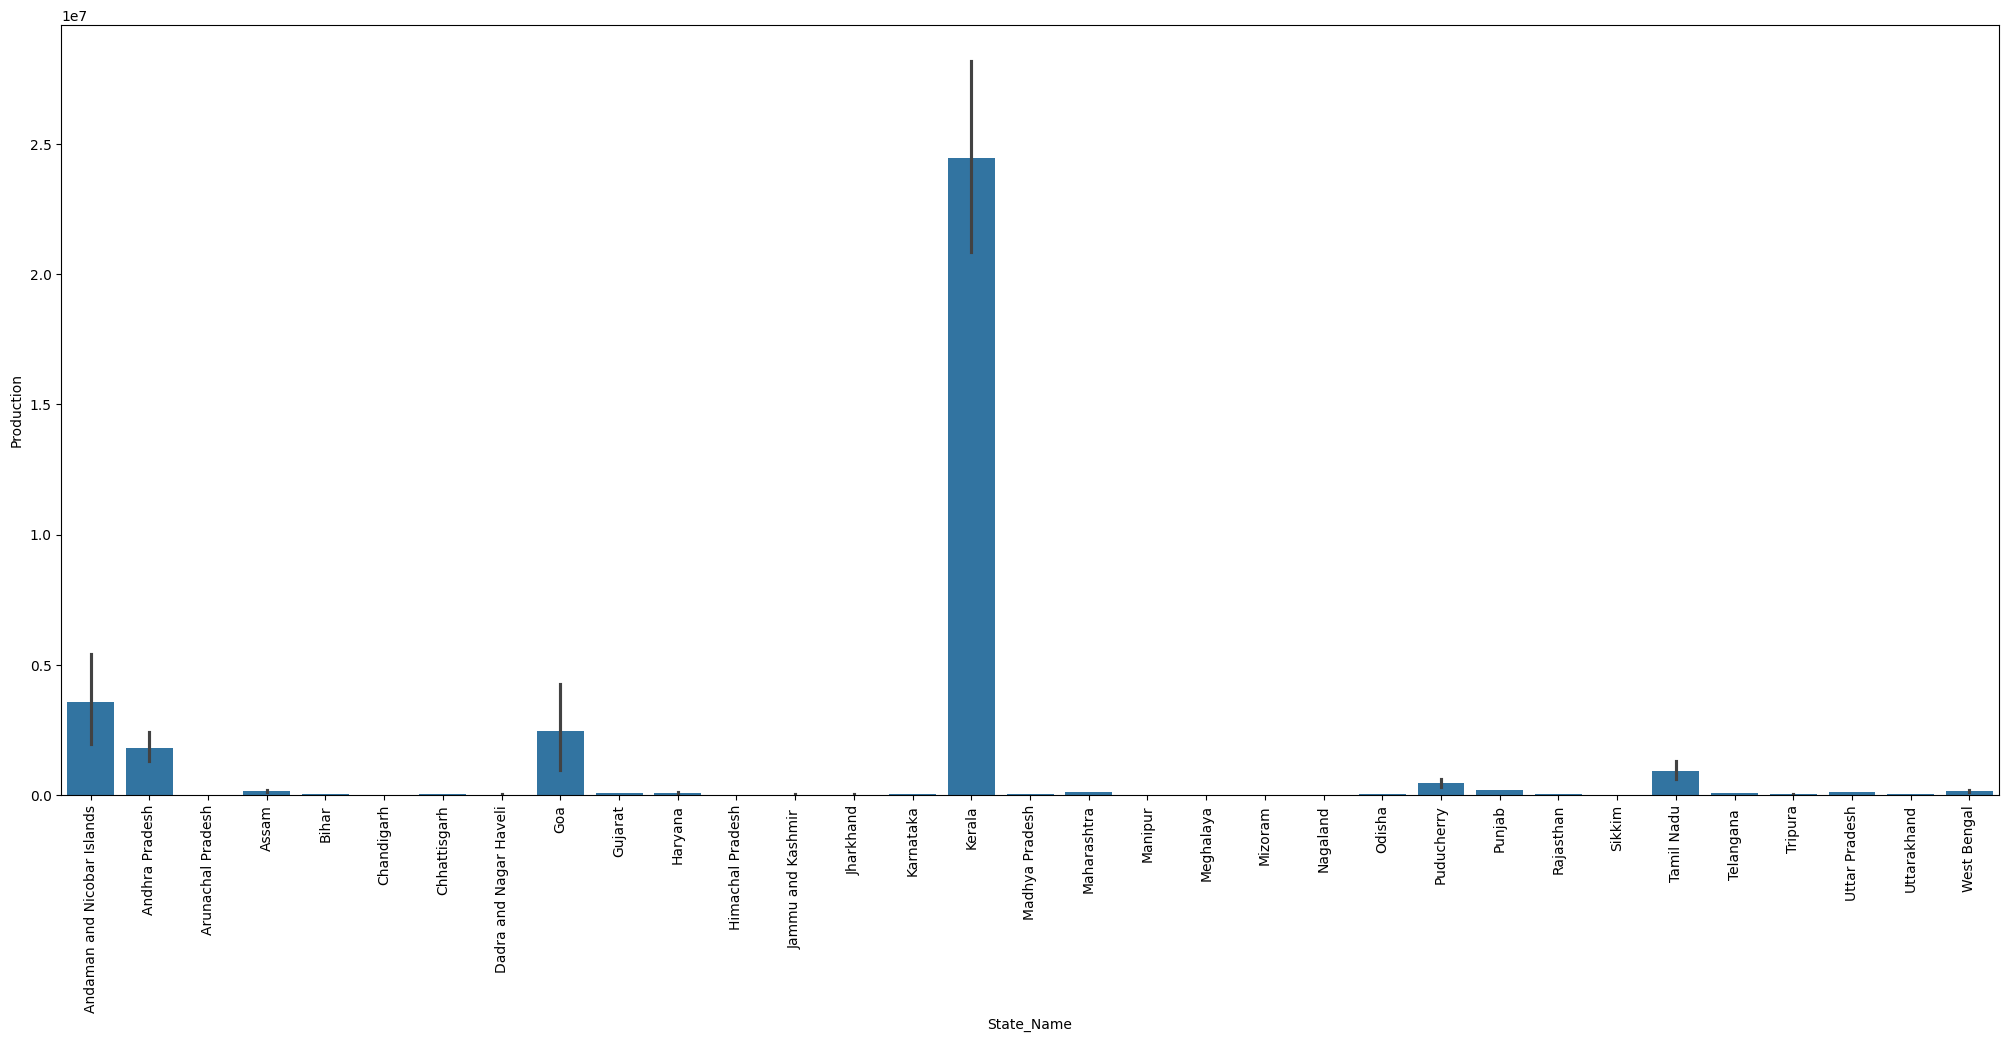

In [ ]:
plt.figure(figsize=(25,10))
sns.barplot(x="State_Name", y="Production", data=data)
plt.xticks(rotation=90)

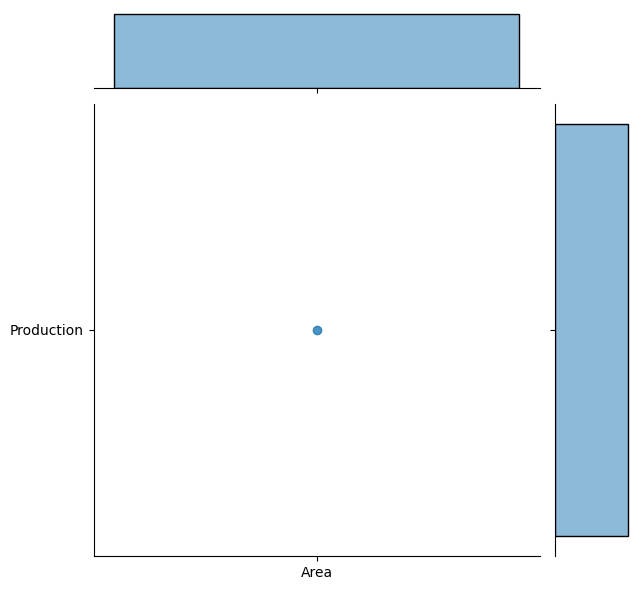

In [ ]:
sns.jointplot(x=["Area"],y=["Production"],kind='reg')

<Axes: xlabel='Season', ylabel='Production'>

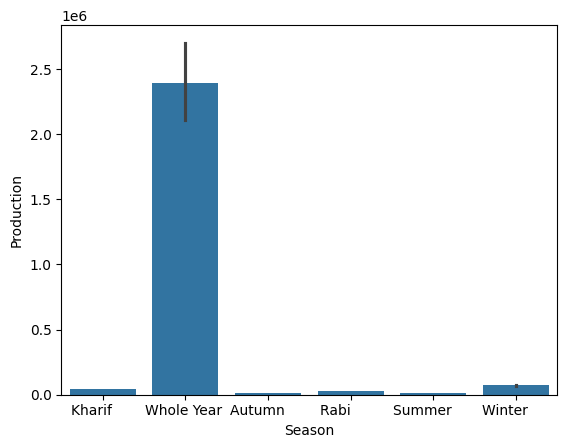

In [ ]:
sns.barplot(x="Season",y="Production",data=data)

In [ ]:
data.groupby("Season",axis=0).agg({"Production":np.sum})


/tmp/ipykernel_1356/2331274168.py:1: FutureWarning: The 'axis' keyword in DataFrame.groupby is deprecated and will be removed in a future version.
  data.groupby("Season",axis=0).agg({"Production":np.sum})
/tmp/ipykernel_1356/2331274168.py:1: FutureWarning: The provided callable <function sum at 0x7eb67b7391c0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  data.groupby("Season",axis=0).agg({"Production":np.sum})


,Production
Season,
Autumn,6.441377e+07
Kharif,4.029970e+09
Rabi,2.051688e+09
Summer,1.706579e+08
Whole Year,1.344248e+11
Winter,4.345498e+08


In [ ]:
data["Crop"].value_counts()[:5]

,count
Crop,
Rice,15082
Maize,13787
Moong(Green Gram),10106
Urad,9710
Sesamum,8821


In [ ]:
top_crop_pro = data.groupby("Crop")["Production"].sum().reset_index().sort_values(by='Production',ascending=False)
top_crop_pro[:5]

,Crop,Production
28,Coconut,1.299816e+11
106,Sugarcane,5.535682e+09
95,Rice,1.605470e+09
119,Wheat,1.332826e+09
87,Potato,4.248263e+08


Each type of crops required various area & various season. so, I'm going to pic top crop from this data

1.Rice

In [ ]:
rice_df = data[data["Crop"]=="Rice"]
print(rice_df.shape)
rice_df[:3]

(15082, 8)


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production,percent_of_production
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.00,2.273756e-07
12,Andaman and Nicobar Islands,NICOBARS,2001,Kharif,Rice,83.0,300.00,2.125005e-07
18,Andaman and Nicobar Islands,NICOBARS,2002,Kharif,Rice,189.2,510.84,3.618459e-07


<Axes: xlabel='Season', ylabel='Production'>

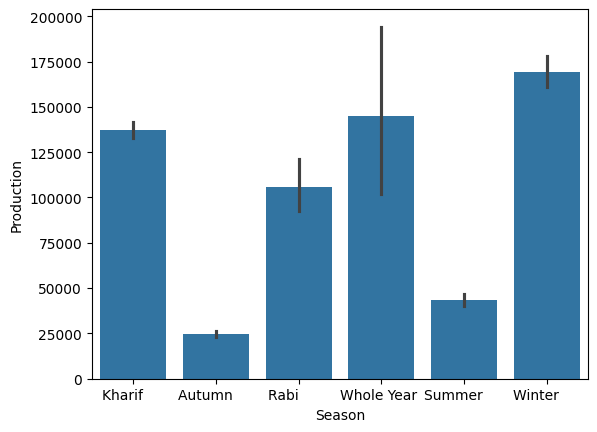

In [ ]:
sns.barplot(x="Season",y="Production",data=rice_df)

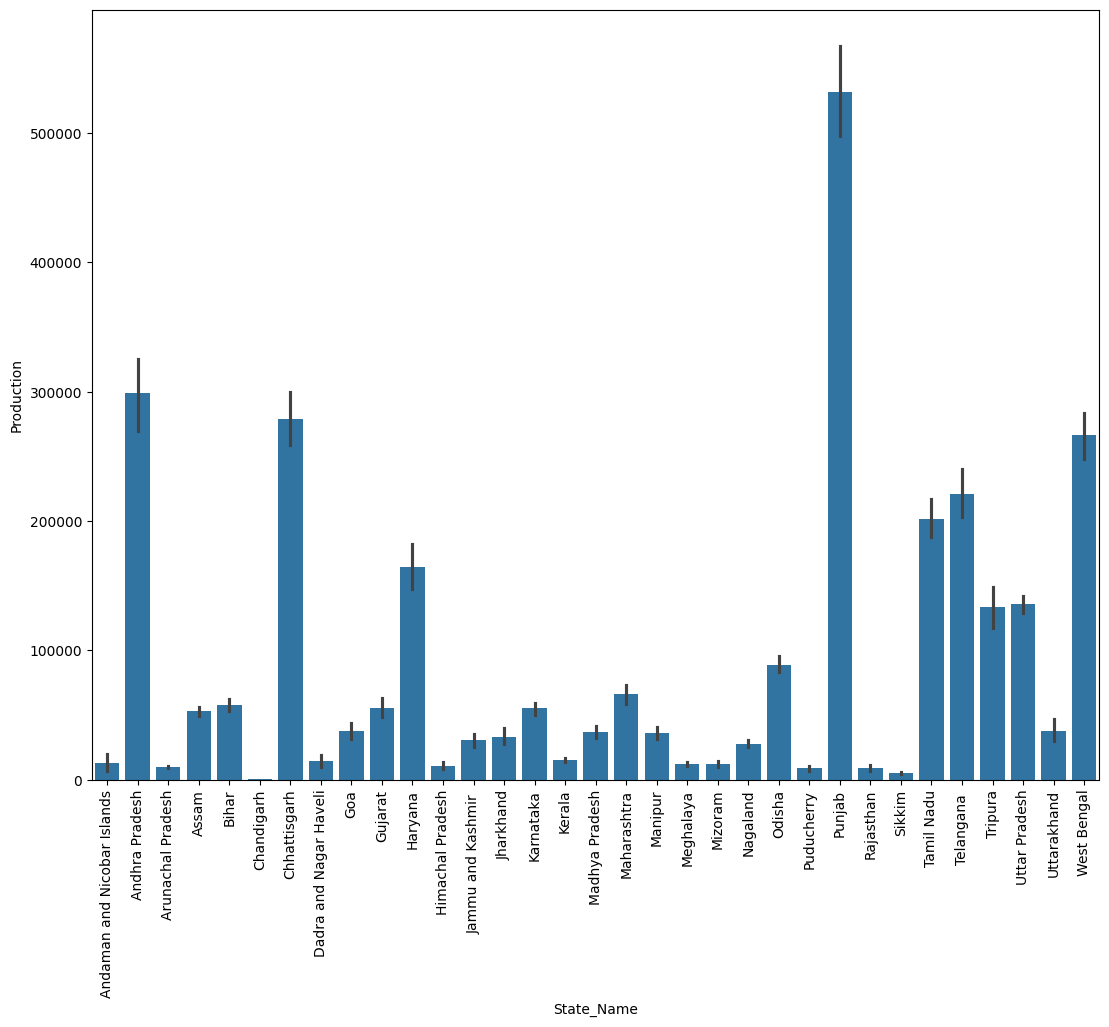

In [ ]:
plt.figure(figsize=(13,10))
sns.barplot(x="State_Name",y="Production",data=rice_df)
plt.xticks(rotation=90)
plt.show()

In [ ]:
top_rice_pro_dis = rice_df.groupby("District_Name")["Production"].sum().reset_index().sort_values(
    by='Production',ascending=False)
top_rice_pro_dis[:5]
sum_max = top_rice_pro_dis["Production"].sum()
top_rice_pro_dis["precent_of_pro"] = top_rice_pro_dis["Production"].map(lambda x:(x/sum_max)*100)
top_rice_pro_dis[:5]

,District_Name,Production,precent_of_pro
58,BARDHAMAN,34239976.0,2.132707
374,MEDINIPUR WEST,29192719.0,1.818328
612,WEST GODAVARI,27845309.0,1.734402
169,EAST GODAVARI,24690929.0,1.537925
494,SANGRUR,24448000.0,1.522794


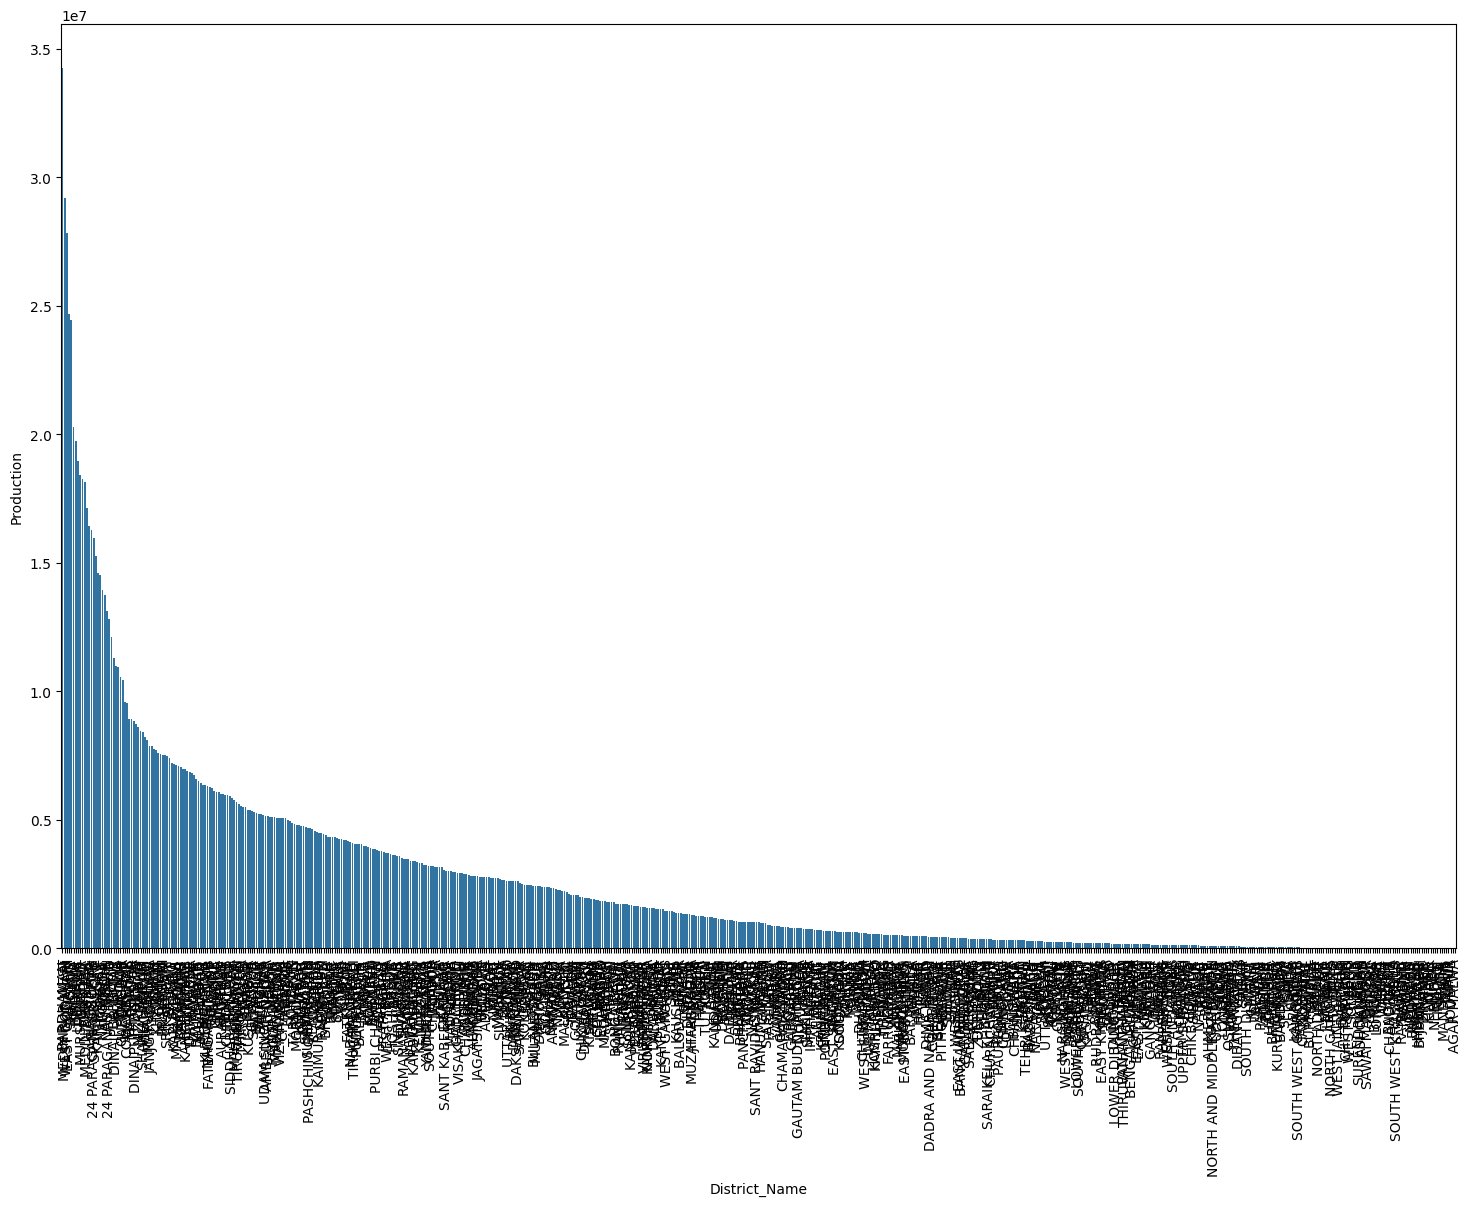

In [ ]:
plt.figure(figsize=(18,12))
sns.barplot(x="District_Name",y="Production",data=top_rice_pro_dis)
plt.xticks(rotation=90)
plt.show()

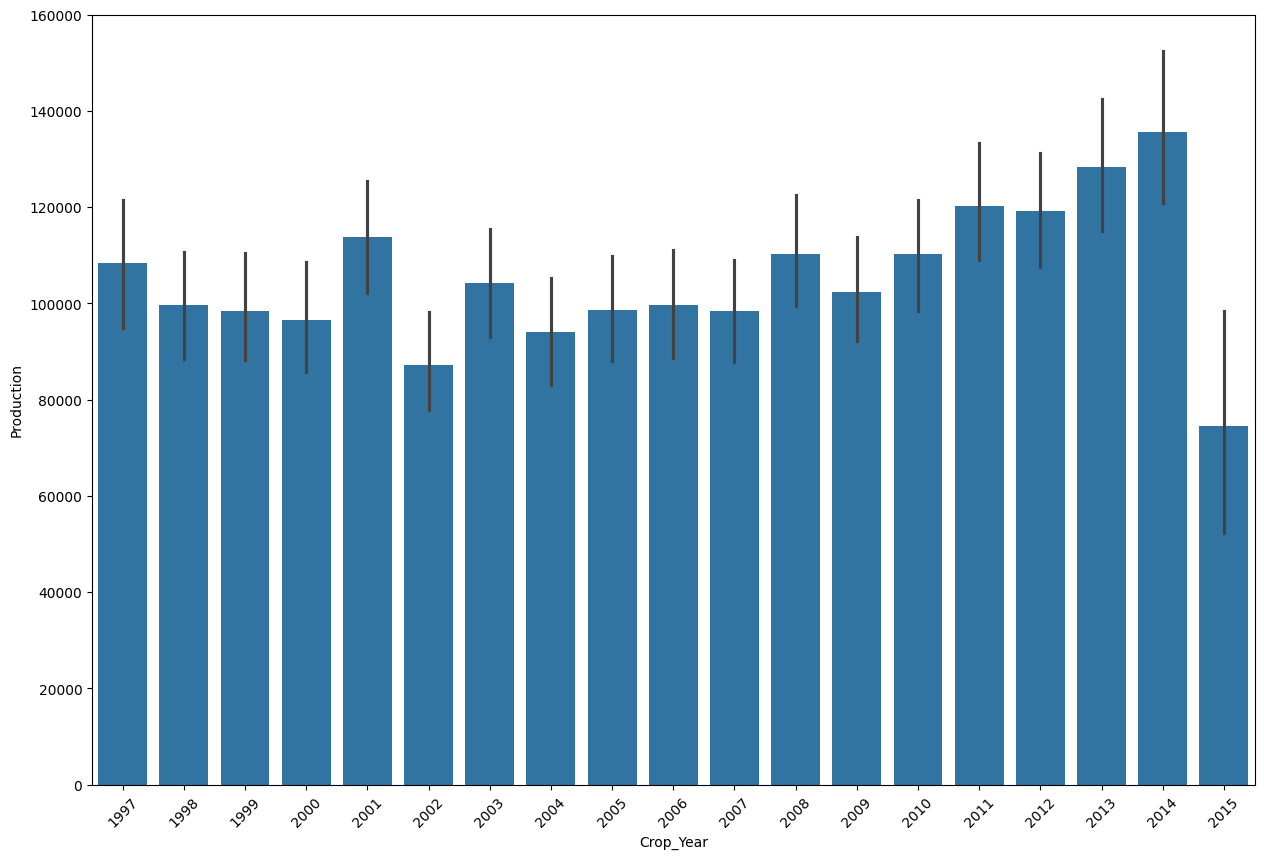

In [ ]:
plt.figure(figsize=(15,10))
sns.barplot(x="Crop_Year",y="Production",data=rice_df)
plt.xticks(rotation=45)
#plt.legend(rice_df['State_Name'].unique())
plt.show()

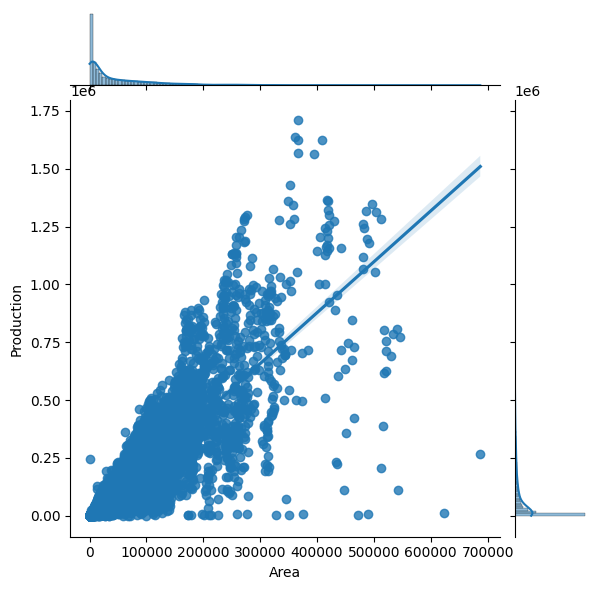

In [ ]:
sns.jointplot(x="Area",y="Production",data=rice_df,kind="reg")

Insights:
From Data Visualization: Rice production is mostly depends on Season, Area, State(place).

2.Coconut

In [ ]:
coc_df = data[data["Crop"]=="Coconut "]
print(coc_df.shape)
coc_df[:3]

(1958, 8)


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production,percent_of_production
5,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Coconut,18168.0,65100000.0,0.046113
14,Andaman and Nicobar Islands,NICOBARS,2001,Whole Year,Coconut,18190.0,64430000.0,0.045638
23,Andaman and Nicobar Islands,NICOBARS,2002,Whole Year,Coconut,18240.0,67490000.0,0.047806


<Axes: xlabel='Season', ylabel='Production'>

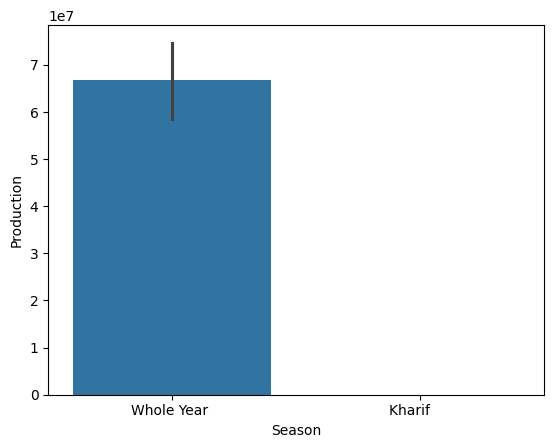

In [ ]:
sns.barplot(x="Season",y="Production",data=coc_df)

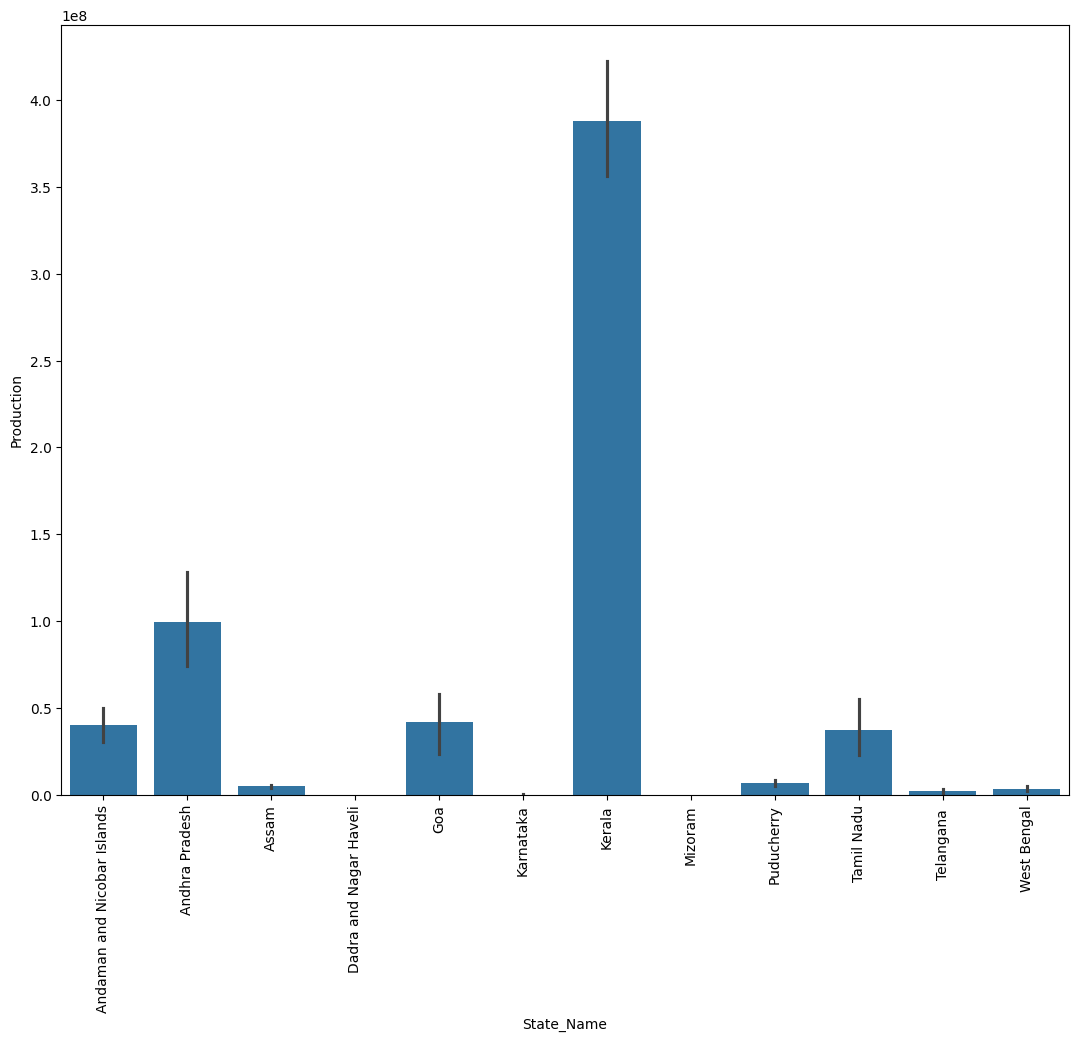

In [ ]:
plt.figure(figsize=(13,10))
sns.barplot(x="State_Name",y="Production",data=coc_df)
plt.xticks(rotation=90)
plt.show()

In [ ]:
top_coc_pro_dis = coc_df.groupby("District_Name")["Production"].sum().reset_index().sort_values(
    by='Production',ascending=False)
top_coc_pro_dis[:5]
sum_max = top_coc_pro_dis["Production"].sum()
top_coc_pro_dis["precent_of_pro"] = top_coc_pro_dis["Production"].map(lambda x:(x/sum_max)*100)
top_coc_pro_dis[:5]

,District_Name,Production,precent_of_pro
77,KOZHIKODE,1.527871e+10,11.754512
86,MALAPPURAM,1.451252e+10,11.165052
129,THIRUVANANTHAPURAM,1.001337e+10,7.703678
131,THRISSUR,9.920739e+09,7.632416
64,KANNUR,9.780310e+09,7.524379


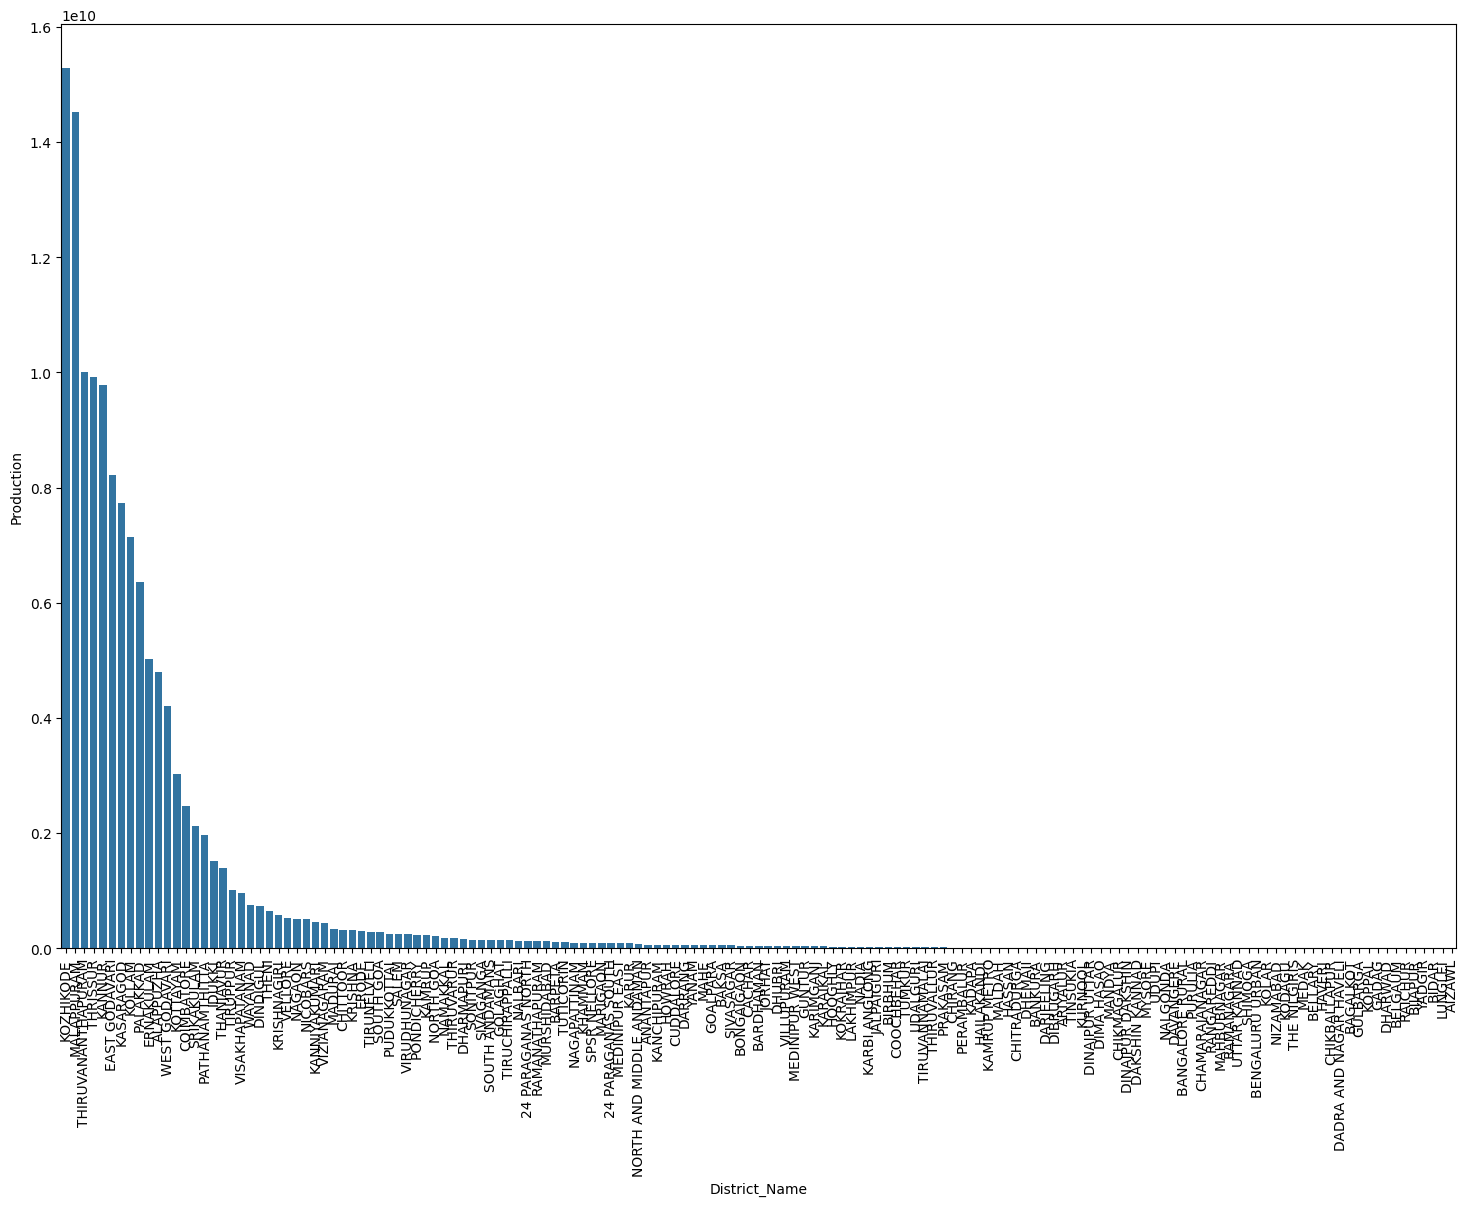

In [ ]:
plt.figure(figsize=(18,12))
sns.barplot(x="District_Name",y="Production",data=top_coc_pro_dis)
plt.xticks(rotation=90)
plt.show()

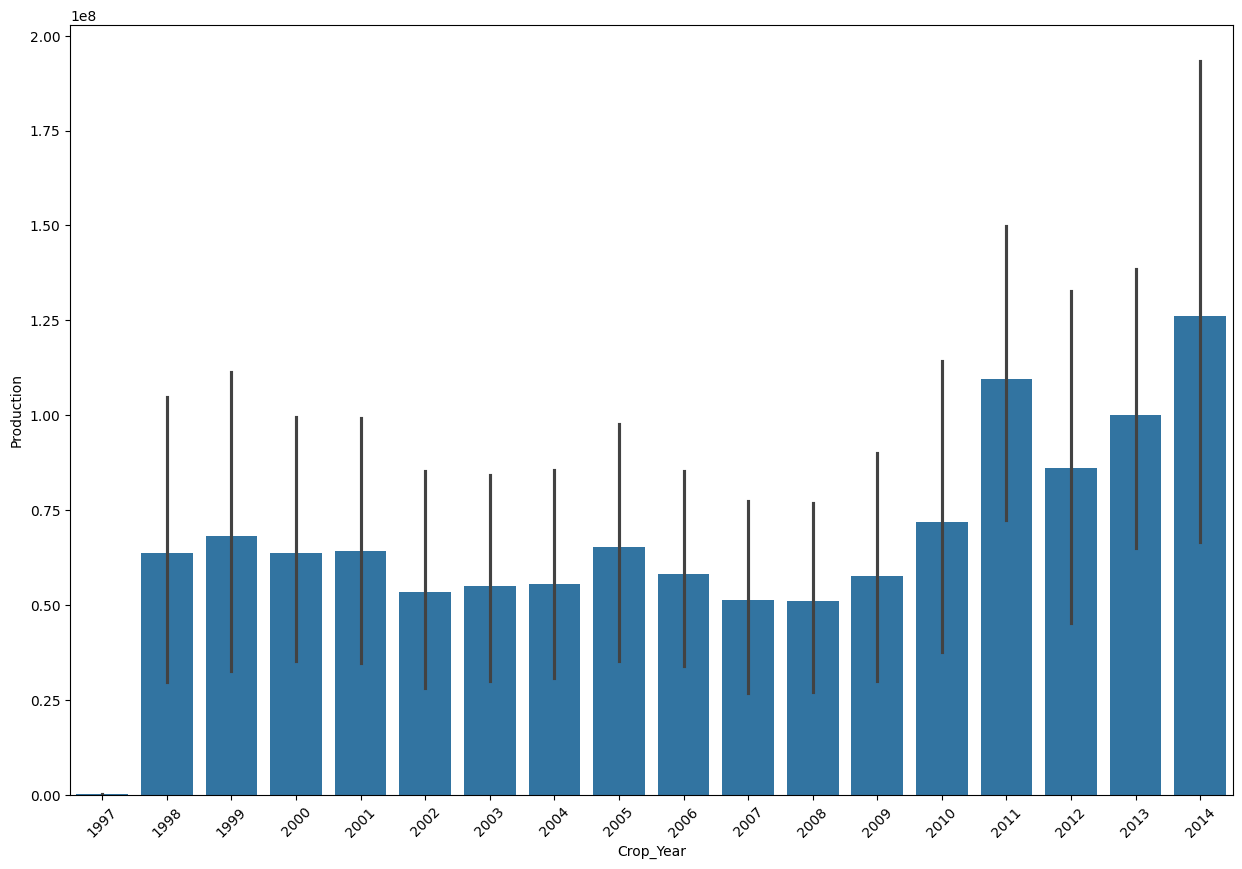

In [ ]:
plt.figure(figsize=(15,10))
sns.barplot(x="Crop_Year",y="Production",data=coc_df)
plt.xticks(rotation=45)
#plt.legend(rice_df['State_Name'].unique())
plt.show()

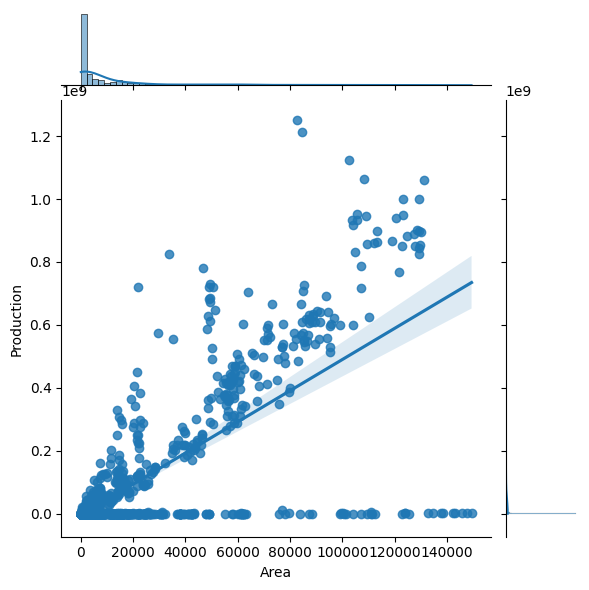

In [ ]:
sns.jointplot(x="Area",y="Production",data=coc_df,kind="reg")

Insights from Coconut Production

cocunut production is directly
proportional to area
its production is also gradually increasing over a time of period
production is highin kerala state
it does not depends on season

3.Sugarcane

In [ ]:
sug_df = data[data["Crop"]=="Sugarcane"]
print(sug_df.shape)
sug_df[:3]

(7827, 8)


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production,percent_of_production
7,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Sugarcane,1.0,2.0,1.416670e-09
16,Andaman and Nicobar Islands,NICOBARS,2001,Whole Year,Sugarcane,1.0,1.0,7.083351e-10
26,Andaman and Nicobar Islands,NICOBARS,2002,Whole Year,Sugarcane,5.0,40.0,2.833340e-08


<Axes: xlabel='Season', ylabel='Production'>

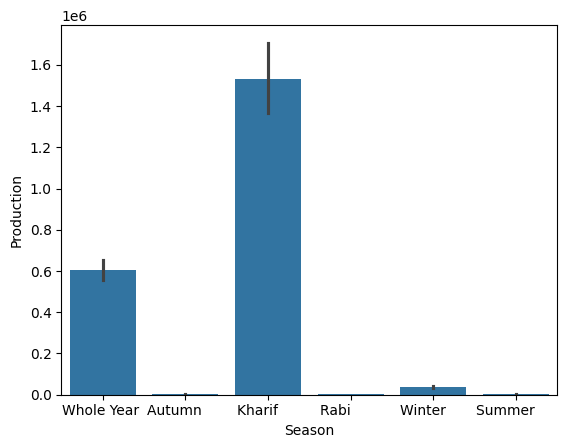

In [ ]:
sns.barplot(x="Season",y="Production",data=sug_df)

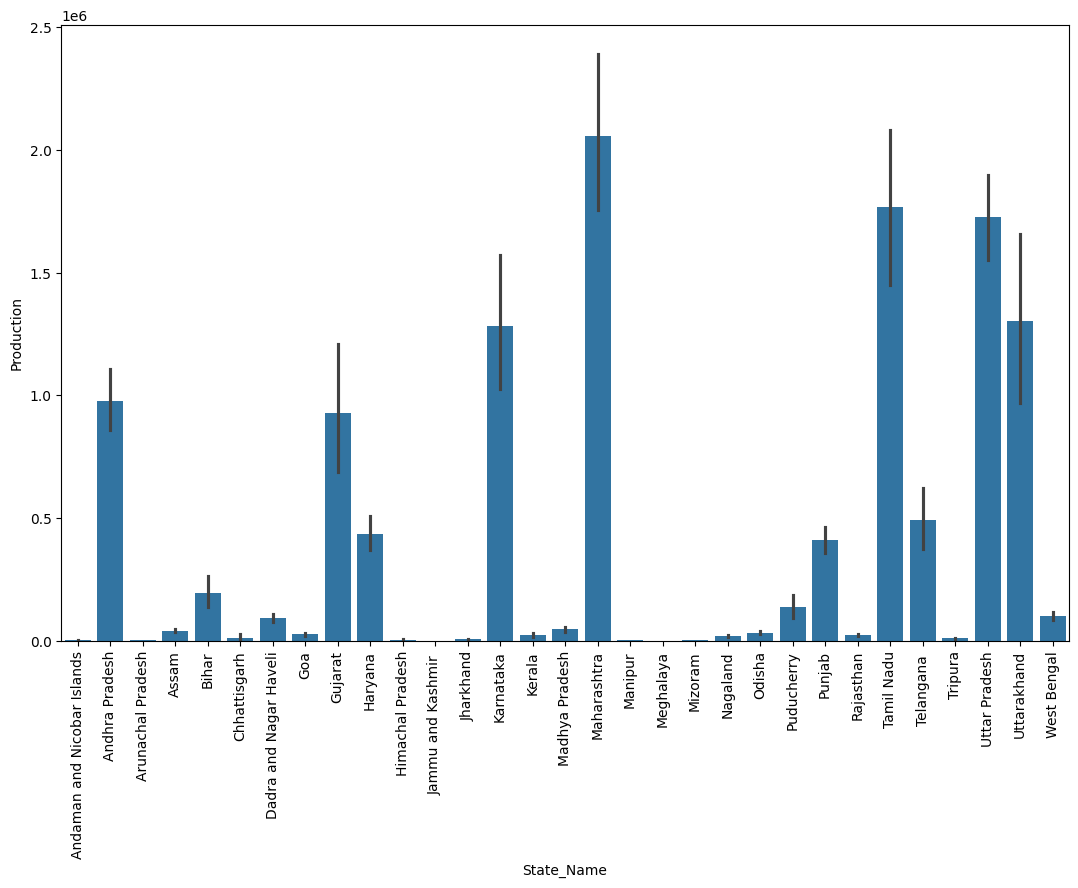

In [ ]:
plt.figure(figsize=(13,8))
sns.barplot(x="State_Name",y="Production",data=sug_df)
plt.xticks(rotation=90)
plt.show()

In [ ]:
top_sug_pro_dis = sug_df.groupby("District_Name")["Production"].sum().reset_index().sort_values(
    by='Production',ascending=False)
top_sug_pro_dis[:5]
sum_max = top_sug_pro_dis["Production"].sum()
top_sug_pro_dis["precent_of_pro"] = top_sug_pro_dis["Production"].map(lambda x:(x/sum_max)*100)
top_sug_pro_dis[:5]

,District_Name,Production,precent_of_pro
360,MUZAFFARNAGAR,258698795.0,4.673296
81,BIJNOR,230907185.0,4.171251
283,KHERI,224383685.0,4.053407
63,BELGAUM,198207649.0,3.580546
294,KOLHAPUR,157210426.0,2.839947


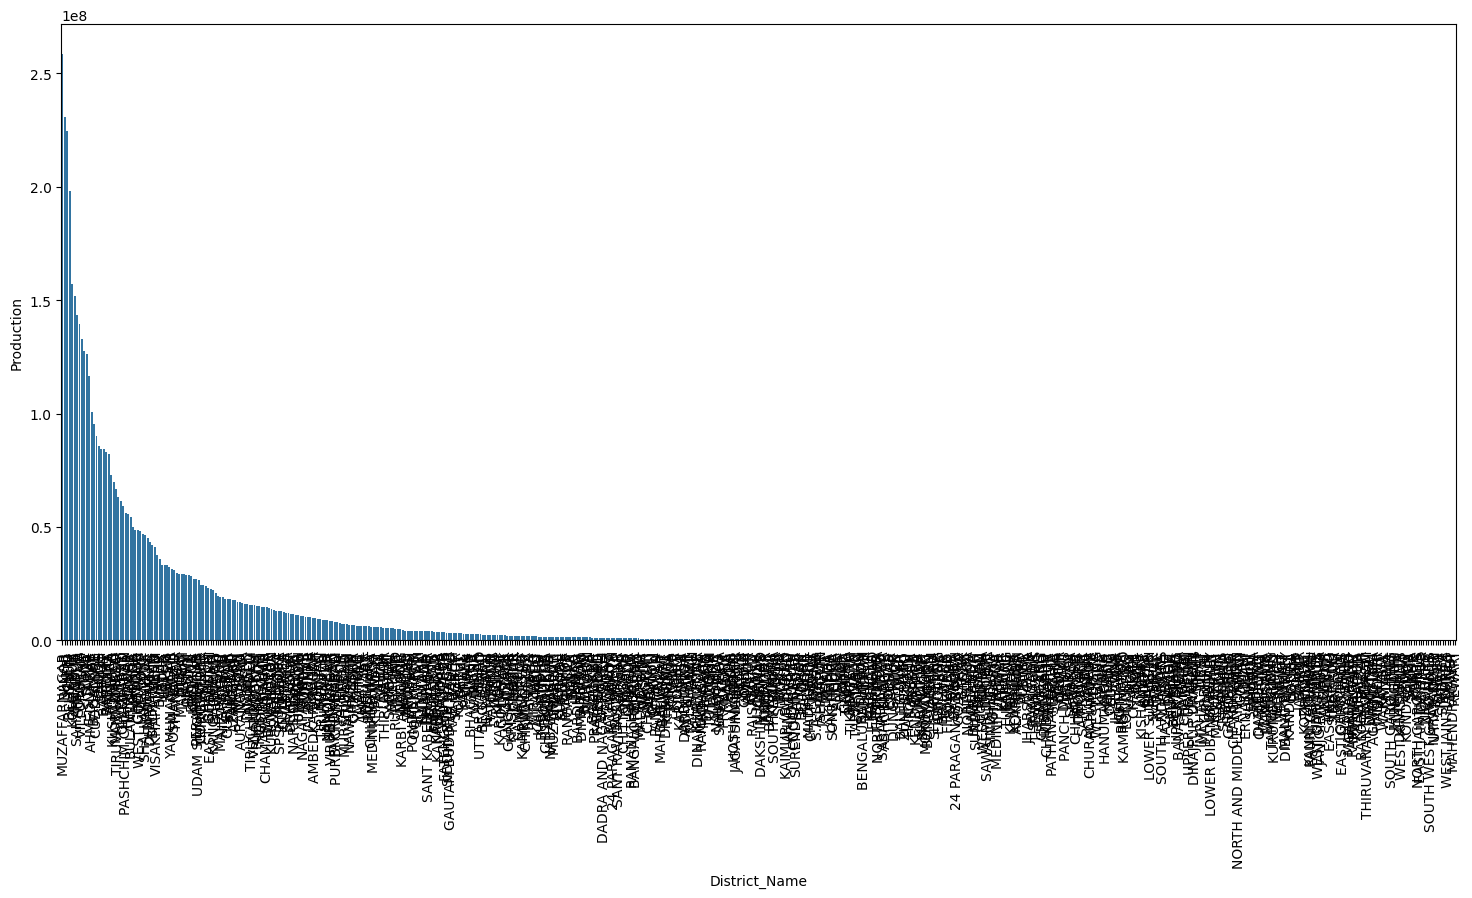

In [ ]:
plt.figure(figsize=(18,8))
sns.barplot(x="District_Name",y="Production",data=top_sug_pro_dis)
plt.xticks(rotation=90)
plt.show()

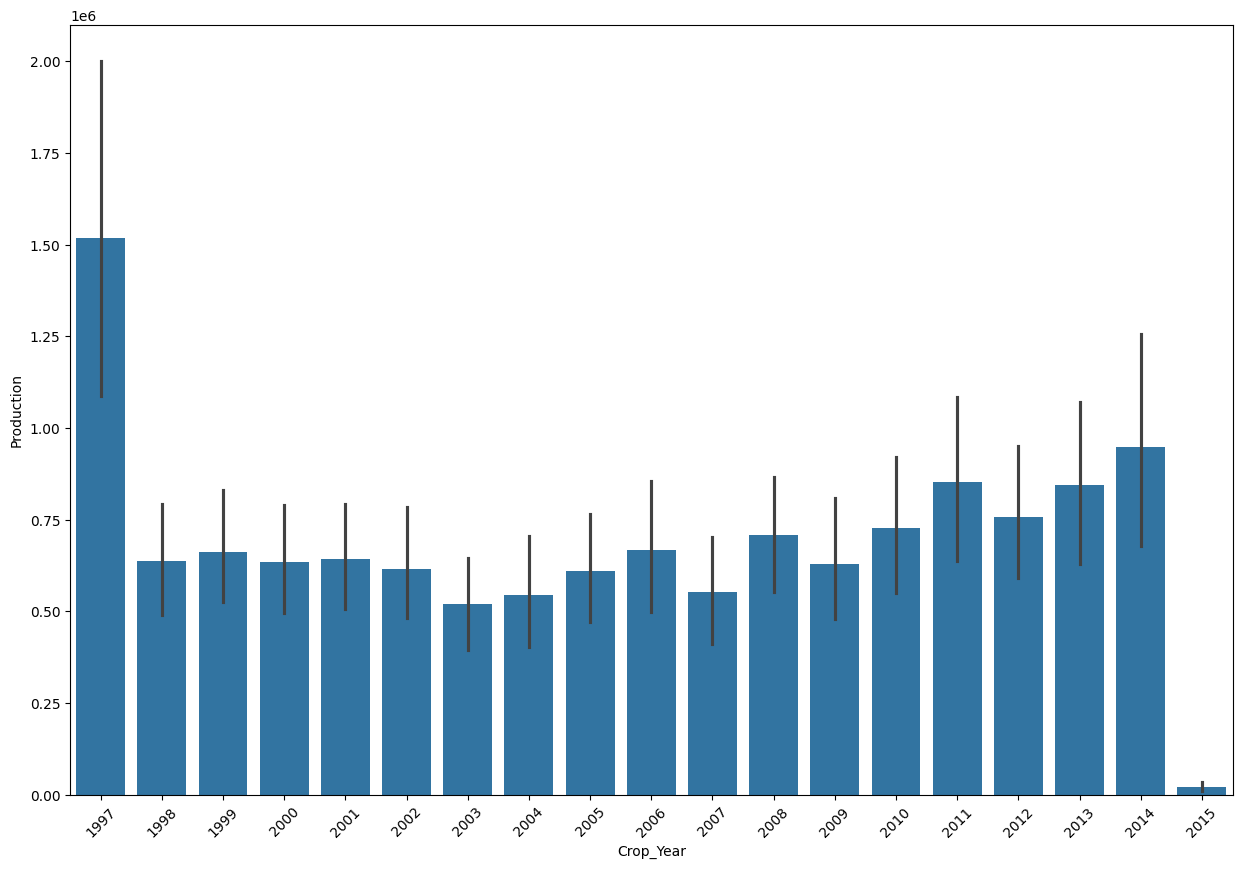

In [ ]:
plt.figure(figsize=(15,10))
sns.barplot(x="Crop_Year",y="Production",data=sug_df)
plt.xticks(rotation=45)
#plt.legend(rice_df['State_Name'].unique())
plt.show()

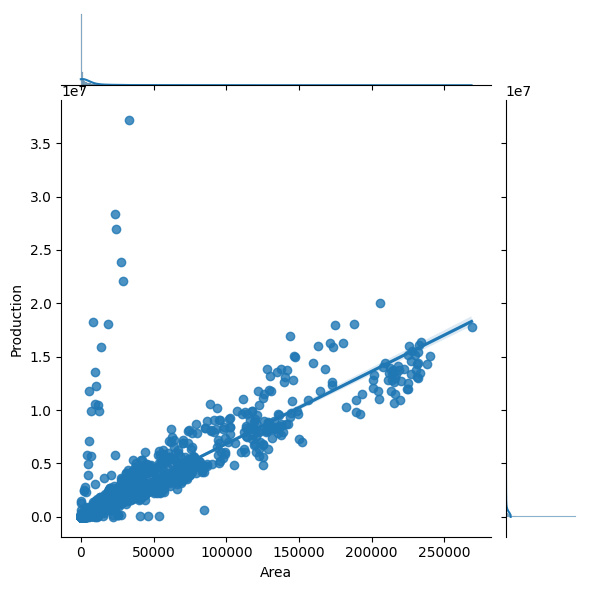

In [ ]:
sns.jointplot(x="Area",y="Production",data=sug_df,kind="reg")

Feature Selection

In [ ]:
data1 = data.drop(["District_Name","Crop_Year"],axis=1)

In [ ]:
data_dum = pd.get_dummies(data1)
data_dum[:5]

,Area,Production,percent_of_production,State_Name_Andaman and Nicobar Islands,State_Name_Andhra Pradesh,State_Name_Arunachal Pradesh,State_Name_Assam,State_Name_Bihar,State_Name_Chandigarh,State_Name_Chhattisgarh,...,Crop_Turmeric,Crop_Turnip,Crop_Urad,Crop_Varagu,Crop_Water Melon,Crop_Wheat,Crop_Yam,Crop_other fibres,Crop_other misc. pulses,Crop_other oilseeds
0,1254.0,2000.0,1.416670e-06,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2.0,1.0,7.083351e-10,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,102.0,321.0,2.273756e-07,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,176.0,641.0,4.540428e-07,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,720.0,165.0,1.168753e-07,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


Train Test Split

In [ ]:
x = data_dum.drop("Production",axis=1)
y = data_dum[["Production"]]
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.33, random_state=42)
print("x_train :",x_train.shape)
print("x_test :",x_test.shape)
print("y_train :",y_train.shape)
print("y_test :",y_test.shape)


x_train : (162381, 165)
x_test : (79980, 165)
y_train : (162381, 1)
y_test : (79980, 1)


In [ ]:
x_train[:5]

,Area,percent_of_production,State_Name_Andaman and Nicobar Islands,State_Name_Andhra Pradesh,State_Name_Arunachal Pradesh,State_Name_Assam,State_Name_Bihar,State_Name_Chandigarh,State_Name_Chhattisgarh,State_Name_Dadra and Nagar Haveli,...,Crop_Turmeric,Crop_Turnip,Crop_Urad,Crop_Varagu,Crop_Water Melon,Crop_Wheat,Crop_Yam,Crop_other fibres,Crop_other misc. pulses,Crop_other oilseeds
4843,785.0,1.486087e-06,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20626,1250.0,5.829598e-07,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
240277,2.0,1.452087e-07,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20664,60.0,4.646678e-07,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
157859,605.0,6.729184e-08,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


model 1: Random Forest Regressor


In [ ]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(x_train, y_train)

rf_preds = rf.predict(x_test)

mean_squared_error(y_test,rf_preds)
r2_score(y_test,rf_preds)

print("Random Forest R2:", r2_score(y_test, rf_preds))
print("Random Forest RMSE:", np.sqrt(mean_squared_error(y_test, rf_preds)))

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Random Forest R2: 0.9975504847044055
Random Forest RMSE: 886021.5907075965


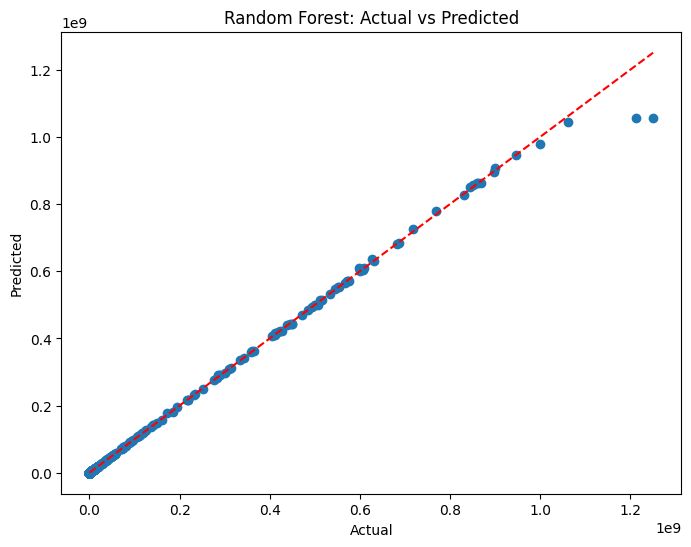

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, rf_preds)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Random Forest: Actual vs Predicted")
plt.show()

model 2: Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train, y_train)

lr_preds = lr.predict(x_test)

mean_squared_error(y_test,lr_preds)
r2_score(y_test,lr_preds)

print("Linear Regression R2:", r2_score(y_test, lr_preds))
print("Linear Regression RMSE:", np.sqrt(mean_squared_error(y_test, lr_preds)))

Linear Regression R2: 1.0
Linear Regression RMSE: 4.6101441537771715e-05


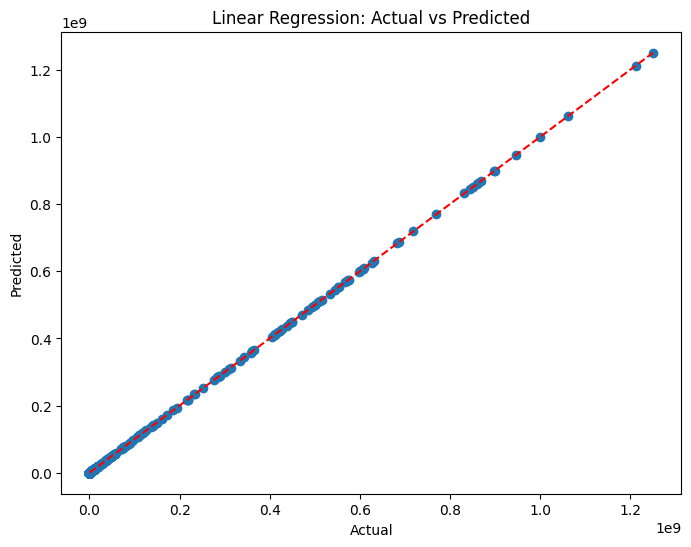

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, lr_preds)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

model 3: Xgboost Regressor

In [ ]:
from xgboost import XGBRegressor
xgb = XGBRegressor(n_estimators=100, random_state=42)
xgb.fit(x_train, y_train)

xgb_preds = xgb.predict(x_test)

mean_squared_error(y_test,xgb_preds)
r2_score(y_test,xgb_preds)

print("XGBoost R2:", r2_score(y_test, xgb_preds))
print("XGBoost RMSE:", np.sqrt(mean_squared_error(y_test, xgb_preds)))

XGBoost R2: 0.904696524143219
XGBoost RMSE: 5526607.403542973


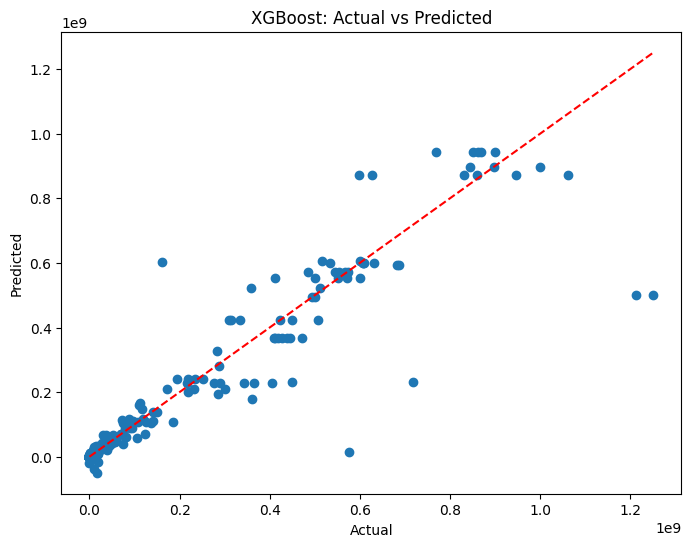

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, xgb_preds)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("XGBoost: Actual vs Predicted")
plt.show()

model 4: Decision Tree Regressor

In [ ]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(random_state=42)
dt.fit(x_train, y_train)

dt_preds = dt.predict(x_test)
mean_squared_error(y_test,dt_preds)
r2_score(y_test,dt_preds)

print("Decision Tree R2:", r2_score(y_test, dt_preds))
print("Decision Tree RMSE:", np.sqrt(mean_squared_error(y_test, dt_preds)))

Decision Tree R2: 0.9988820274428243
Decision Tree RMSE: 598576.687645973


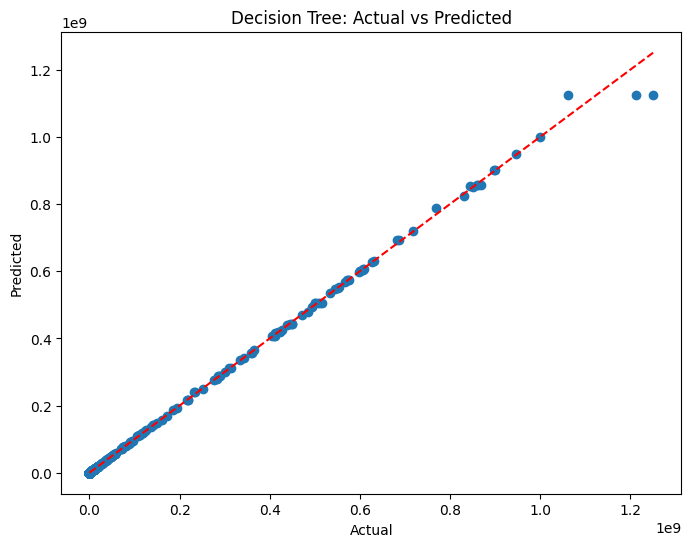

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, dt_preds)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Decision Tree: Actual vs Predicted")
plt.show()

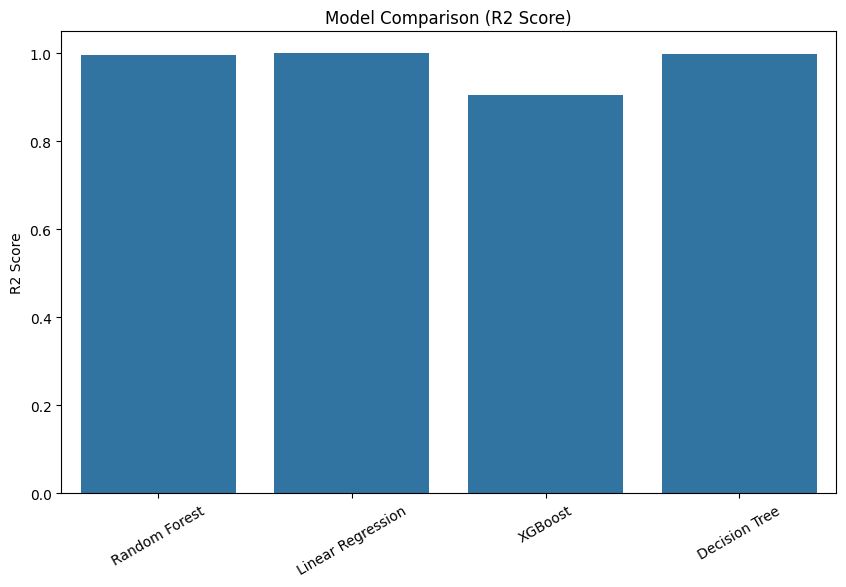

In [ ]:
r2_scores = [
    r2_score(y_test, rf_preds),
    r2_score(y_test, lr_preds),
    r2_score(y_test, xgb_preds),
    r2_score(y_test, dt_preds)
]

models = ['Random Forest', 'Linear Regression', 'XGBoost', 'Decision Tree']

plt.figure(figsize=(10,6))
sns.barplot(x=models, y=r2_scores)
plt.title("Model Comparison (R2 Score)")
plt.ylabel("R2 Score")
plt.xticks(rotation=30)
plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error

# Calculate MSE
rf_mse = mean_squared_error(y_test, rf_preds)
lr_mse = mean_squared_error(y_test, lr_preds)
xgb_mse = mean_squared_error(y_test, xgb_preds)
dt_mse = mean_squared_error(y_test, dt_preds)

# Store in list
mse_values = [rf_mse, lr_mse, xgb_mse, dt_mse]

models = ['Random Forest', 'Linear Regression', 'XGBoost', 'Decision Tree']

print("Random Forest MSE:", rf_mse)
print("Linear Regression MSE:", lr_mse)
print("XGBoost MSE:", xgb_mse)
print("Decision Tree MSE:", dt_mse)

Random Forest MSE: 785034259200.0197
Linear Regression MSE: 2.125342911860583e-09
XGBoost MSE: 30543389392896.0
Decision Tree MSE: 358294050993.2248


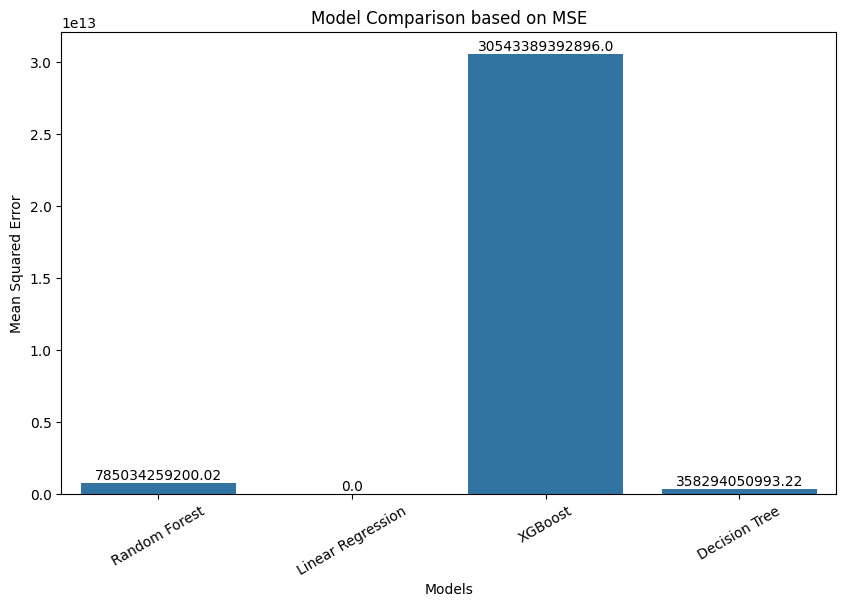

In [ ]:
plt.figure(figsize=(10,6))
sns.barplot(x=models, y=mse_values)

plt.title("Model Comparison based on MSE")
plt.ylabel("Mean Squared Error")
plt.xlabel("Models")
plt.xticks(rotation=30)

# Display value on bars
for i, value in enumerate(mse_values):
    plt.text(i, value, round(value, 2), ha='center', va='bottom')

plt.show()